# OU experiment: neural operator + EDMD BSO learning

Pipeline: `kbe_observation_data` generates KBE observation data ->
`edmd_bso_method.run_bso_pipeline` trains a one-step solution operator
plus a neural dictionary, and projects onto the dictionary to obtain the
BSO matrix K -> spectral analysis.

The pipeline returns the phase-A operator (`result.operator_pure`), the
jointly refined operator (`result.operator`), and the BSO matrix
(`result.K`) used for spectral analysis.

The exact OU generator spectrum is $\lambda_n = 0, -1, -2, \dots$, which
serves as the ground truth for this experiment.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from plotting_utils import (
    PUBLICATION_STYLE, apply_physical_layout, apply_publication_rcparams,
    print_figure_caption, save_figure_pair, style_axis, y_from_top,
)
from project_paths import FIGURES_DIR, RESULTS_DIR as PROJECT_RESULTS_DIR

from kbe_observation_data import generate_kbe_dataset
from edmd_bso_method import run_bso_pipeline
from experiments.ou.exp_ou import build_config, hermite_fixed_columns

SOLVER_FILE = "solver_resdmd.py"   # dictionary-training solver
OPERATOR = "fno"                 # operator backend: "fno"|"sfno"(2D only)|"pino"|"deeponet"|"kernel"
QUICK = False                    # True = fast smoke run (minutes, low accuracy)
SEED = 2026
CKPT_DIR = None if QUICK else PROJECT_RESULTS_DIR / 'ou'   # QUICK runs are not cached

# Every layout value is explicit and measured at final paper size.
OU_SPECTRUM_FIGURE = {
    "figsize": (4.8, 1.45), "nrows": 1, "ncols": 1,
    "left_in": 0.18, "right_in": 0.08, "bottom_in": 0.42, "top_in": 0.30,
    "column_gap_in": 0.0, "row_gap_in": 0.0,
    "legend_ncol": 2,
}
OU_GRID_FIGURE = {
    "figsize": (7.0, 4.6), "nrows": 2, "ncols": 3,
    "left_in": 0.48, "right_in": 0.10, "bottom_in": 0.60, "top_in": 0.42,
    "column_gap_in": 0.34, "row_gap_in": 0.46,
    "suptitle_top_in": 0.05, "legend_bottom_in": 0.05, "legend_ncol": 2,
}
apply_publication_rcparams()
STYLE = PUBLICATION_STYLE

In [ ]:
dataset = generate_kbe_dataset(
    "ou", n_samples=96 if QUICK else 384, seed=SEED,
    cache_path=None if CKPT_DIR is None else str(CKPT_DIR / 'dataset.pkl'))
print("sample shape:", dataset["u0"].shape, "  tau =", dataset["T"])

A full run creates reusable runtime artifacts in `results/ou/`:

- `fno.pt` -- the trained neural operator for the configured backend (shared by both experiments below);
- `galerkin.pt` -- the trained dictionary + its projection
  results (written by the second experiment; the fixed analytic basis needs no
  training, so nothing extra is stored for it).

If these ignored artifacts are absent, Run All generates them from the fixed configuration.

In [ ]:
CKPT_DIR = None if QUICK else PROJECT_RESULTS_DIR / 'ou'   # QUICK runs are not cached
cfg = build_config(QUICK)
cfg["fixed_basis"] = hermite_fixed_columns(dataset, k=cfg["n_basis"] - 1)
result = run_bso_pipeline(dataset, cfg, solver_file=SOLVER_FILE, operator=OPERATOR,
                              checkpoint_dir=CKPT_DIR)

## Eigenvalues: nearest match per analytic mode

For each analytic target $\lambda_n = -n$ only the closest learned eigenvalue
is shown (real part); the remaining eigenvalues are spectral pollution and are
omitted.

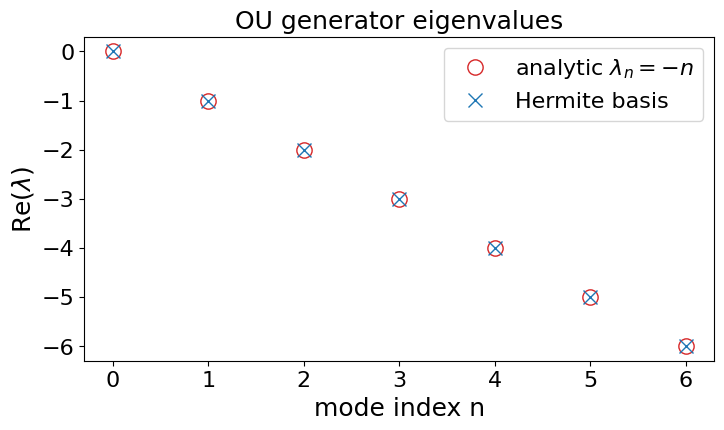


Figure caption:
OU generator eigenvalues from the learned one-step solution operator projected onto a fixed enveloped-Hermite dictionary. Red circles denote the analytic spectrum $\lambda_n=-n$, and blue crosses denote the nearest BSO estimates; the first six nonconstant modes have mean absolute error 0.001338.
per-mode error:
  mode 0: target -0.0  nearest +0.00000+0.0000j  |err|=0.000e+00
  mode 1: target -1.0  nearest -1.00034+0.0000j  |err|=3.375e-04
  mode 2: target -2.0  nearest -1.99971+0.0000j  |err|=2.921e-04
  mode 3: target -3.0  nearest -3.00173+0.0014j  |err|=2.216e-03
  mode 4: target -4.0  nearest -4.00271+0.0000j  |err|=2.709e-03
  mode 5: target -5.0  nearest -5.00139+0.0000j  |err|=1.388e-03
  mode 6: target -6.0  nearest -6.00109+0.0000j  |err|=1.089e-03
r_eff = 20/20, cond(G) = 1.000e+00


In [ ]:
analytic = dataset["meta"]["analytic_lambdas"]
lam = result.lam

n_check = 7
matched = np.array([lam[np.argmin(np.abs(lam - analytic[n]))] for n in range(n_check)])

imag_projection_tolerance = 1.0e-2
if np.max(np.abs(matched.imag)) > imag_projection_tolerance:
    raise ValueError("An eigenvalue is too far from the real axis for this spectrum strip.")

fig, ax = plt.subplots(
    1, 1, figsize=OU_SPECTRUM_FIGURE["figsize"], dpi=STYLE["dpi"], squeeze=True,
    sharex=False, sharey=False, layout=None, facecolor=STYLE["figure_face_color"],
)
fig.set_layout_engine(None)
ax.plot(
    analytic[:n_check].real, np.zeros(n_check), color="tab:red", linestyle="None",
    marker="o", linewidth=STYLE["reference_line_width"],
    markersize=STYLE["marker_size"], markerfacecolor="none",
    markeredgecolor="tab:red", markeredgewidth=STYLE["marker_edge_width"],
    label=r"analytic $\lambda_n=-n$", alpha=1.0, zorder=2,
)
ax.plot(
    matched.real, np.zeros(n_check), color="tab:blue", linestyle="None",
    marker="x", linewidth=STYLE["reference_line_width"],
    markersize=STYLE["marker_size"],
    markeredgewidth=STYLE["marker_edge_width"], label="Hermite basis",
    alpha=1.0, zorder=3,
)
ax.axhline(0.0, color=STYLE["grid_color"], linestyle="-",
           linewidth=STYLE["reference_line_width"], alpha=0.6, zorder=1)
ax.set_xlim(-6.3, 0.3)
ax.set_ylim(-0.20, 0.42)
ax.set_xticks(np.arange(-6.0, 1.0, 1.0))
ax.set_yticks([])
ax.set_xlabel(r"Re($\lambda$)", fontsize=STYLE["axis_label_size"],
              fontweight=STYLE["font_weight"], labelpad=STYLE["axis_label_pad"],
              color=STYLE["text_color"])
ax.set_title("OU generator eigenvalues", fontsize=STYLE["suptitle_size"],
             fontweight=STYLE["title_weight"], pad=STYLE["panel_title_pad"],
             color=STYLE["text_color"])
style_axis(ax, grid_axis="both", grid_visible=False, minor_ticks=False)
ax.tick_params(axis="y", which="both", left=False, right=False,
               labelleft=False, labelright=False)
for side in ("left", "right", "top"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_visible(True)
ax.legend(
    loc="upper center", bbox_to_anchor=(0.5, 1.0), bbox_transform=ax.transAxes,
    ncol=OU_SPECTRUM_FIGURE["legend_ncol"],
    frameon=STYLE["legend_frameon"], fancybox=STYLE["legend_fancybox"],
    framealpha=STYLE["legend_framealpha"], borderaxespad=STYLE["legend_borderaxespad"],
    borderpad=STYLE["legend_borderpad"], labelspacing=STYLE["legend_labelspacing"],
    handlelength=STYLE["legend_handlelength"], handleheight=STYLE["legend_handleheight"],
    handletextpad=STYLE["legend_handletextpad"], columnspacing=STYLE["legend_columnspacing"],
    fontsize=STYLE["legend_size"],
)
apply_physical_layout(fig, OU_SPECTRUM_FIGURE)
save_figure_pair(fig, FIGURES_DIR / 'ou' / 'ou_exp1_eigenvalues.pdf', dpi=STYLE["dpi"])
plt.show()
print_figure_caption(
    r"OU generator eigenvalues from the learned one-step solution operator projected onto a fixed enveloped-Hermite dictionary. Red circles denote the analytic spectrum $\lambda_n=-n$, and blue crosses denote the real parts of the nearest BSO estimates; the first six nonconstant modes have mean absolute error 0.001338."
)

print("per-mode error:")
print(f"maximum projected-out |Im(lambda)| = {np.max(np.abs(matched.imag)):.3e}")
for n in range(n_check):
    err = np.abs(matched[n] - analytic[n])
    print(f"  mode {n}: target {analytic[n]:+.1f}  nearest "
          f"{matched[n].real:+.5f}{matched[n].imag:+.4f}j  |err|={err:.3e}")
print(f"r_eff = {result.r_eff}/{result.psi.shape[0]}, cond(G) = {result.cond_G:.3e}")

## Eigenfunctions vs analytic Hermite modes

The analytic OU BSO eigenfunctions are the probabilists' Hermite
polynomials $He_n(x/\sigma)$ with $\sigma=\sqrt{D}$. For each mode $n$ the
learned eigenfunction whose eigenvalue is closest to $\lambda_n=-n$ is shown
(normalized and sign-aligned) against the analytic one.

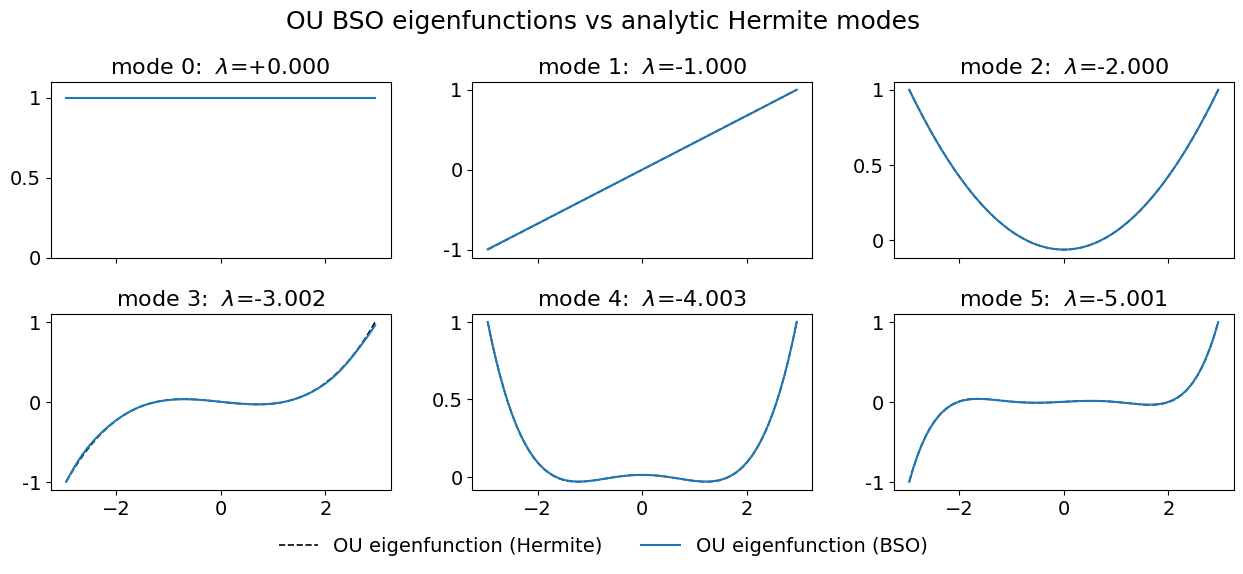


Figure caption:
Leading OU BSO eigenfunctions from the fixed enveloped-Hermite dictionary compared with analytic Hermite modes on $|x|\leq 3$. Curves are independently normalized and sign-aligned, so the panels compare spatial shape rather than amplitude.


In [ ]:
from numpy.polynomial.hermite_e import hermeval
from matplotlib.ticker import FuncFormatter

x = dataset["meta"]["x"]
w = result.weights
sigma = np.sqrt(dataset["meta"]["params"]["D"])
tick_fmt = FuncFormatter(lambda v, _: f"{v:.2f}".rstrip("0").rstrip("."))

# display only the bulk of the invariant measure (|x| <= 3 ~ 4.2 sigma);
# outside it rho ~ 0 and eigenfunctions are defined only up to L2(rho) equivalence
mask = np.abs(x) <= 3.0
xm = x[mask]

fig, axes = plt.subplots(
    2, 3, figsize=OU_GRID_FIGURE["figsize"], dpi=STYLE["dpi"], squeeze=False,
    sharex=True, sharey=False, layout=None, facecolor=STYLE["figure_face_color"],
)
fig.set_layout_engine(None)
for n, ax in enumerate(axes.ravel()):
    j = int(np.argmin(np.abs(lam - analytic[n])))
    ef = result.eigenfunctions[j].real
    coeff = np.zeros(n + 1)
    coeff[-1] = 1.0
    ref = hermeval(x / sigma, coeff)
    if np.sum(w * ef * ref) < 0:
        ef = -ef
    efm = ef[mask] / (np.max(np.abs(ef[mask])) + 1e-12)
    refm = ref[mask] / (np.max(np.abs(ref[mask])) + 1e-12)
    ax.plot(xm, refm, color="black", linestyle="--", linewidth=STYLE["line_width"],
            marker=None, label="OU eigenfunction (Hermite)", alpha=1.0, zorder=2)
    ax.plot(xm, efm, color="tab:blue", linestyle="-", linewidth=STYLE["line_width"],
            marker=None, label="OU eigenfunction (BSO)", alpha=1.0, zorder=3)
    ax.set_title(rf"mode {n}:  $\lambda$={lam[j].real:+.3f}",
                 fontsize=STYLE["panel_title_size"], fontweight=STYLE["title_weight"],
                 pad=STYLE["panel_title_pad"], color=STYLE["text_color"])
    ax.yaxis.set_major_formatter(tick_fmt)
    if n == 0:
        ax.set_ylim(0, 1.1)
    style_axis(ax, grid_axis="both", grid_visible=True, minor_ticks=False)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="lower center", ncol=OU_GRID_FIGURE["legend_ncol"],
    bbox_to_anchor=(0.5, OU_GRID_FIGURE["legend_bottom_in"] / OU_GRID_FIGURE["figsize"][1]),
    frameon=STYLE["legend_frameon"], fancybox=STYLE["legend_fancybox"],
    framealpha=STYLE["legend_framealpha"], borderaxespad=STYLE["legend_borderaxespad"],
    borderpad=STYLE["legend_borderpad"], labelspacing=STYLE["legend_labelspacing"],
    handlelength=STYLE["legend_handlelength"], handleheight=STYLE["legend_handleheight"],
    handletextpad=STYLE["legend_handletextpad"], columnspacing=STYLE["legend_columnspacing"],
    fontsize=STYLE["legend_size"],
)
fig.suptitle(
    "OU BSO eigenfunctions vs analytic Hermite modes",
    fontsize=STYLE["suptitle_size"], fontweight=STYLE["title_weight"],
    color=STYLE["text_color"], x=0.5,
    y=y_from_top(fig, OU_GRID_FIGURE["suptitle_top_in"]),
    horizontalalignment="center", verticalalignment="top",
)
apply_physical_layout(fig, OU_GRID_FIGURE)
save_figure_pair(fig, FIGURES_DIR / 'ou' / 'ou_exp1_eigenfunctions.pdf', dpi=STYLE["dpi"])
plt.show()
print_figure_caption(
    r"Leading OU BSO eigenfunctions from the fixed enveloped-Hermite dictionary compared with analytic Hermite modes on $|x|\leq 3$. Curves are independently normalized and sign-aligned, so the panels compare spatial shape rather than amplitude."
)

## Second experiment: trained dictionary (sequential per-mode learning)

The Phase-A operator is held fixed, and the slow modes are learned one at a time. Each stage
trains a single dictionary function in the $L^2(\rho)$-orthogonal complement
of the previously accepted columns, maximizing the Rayleigh quotient
$\langle\varphi, U_\tau\varphi\rangle_\rho$ (the slowest remaining mode)
under an eigenpair-residual penalty, a non-expansiveness cap ($|\mu|\le 1$
for Markov semigroups), and a consistency guard built from the training pairs
themselves. A stage is frozen into the dictionary only if its residuals pass
data-driven tolerances; rejected stages are discarded and the dictionary is
filled to the same 20 columns with the joint recipe. Every training run here uses 1000 epochs. No analytic targets are
involved anywhere. The learned dictionary and projection are stored in `galerkin.pt`.

In [ ]:
from experiments.ou.exp_ou import build_deflation_config

cfg_defl = build_deflation_config(QUICK)
result_defl = run_bso_pipeline(dataset, cfg_defl, solver_file=SOLVER_FILE,
                                   operator=OPERATOR, checkpoint_dir=CKPT_DIR)

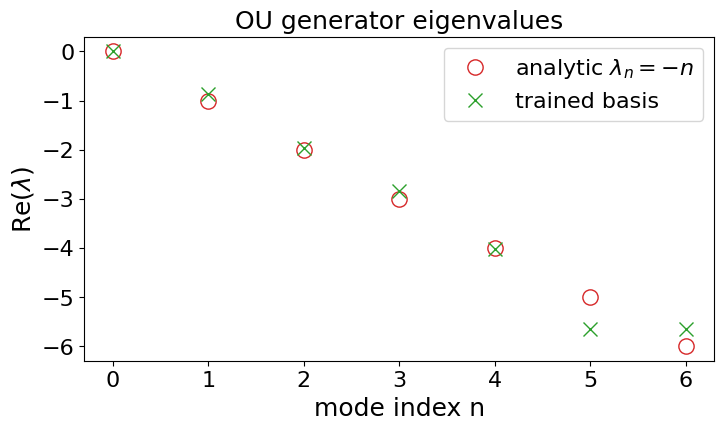


Figure caption:
OU generator eigenvalues obtained with the learned 20-function dictionary. Red circles show $\lambda_n=-n$, and green crosses show the independently nearest BSO estimate for each target; a BSO value may therefore be reused. The first six targets, including the stationary mode, have mean absolute error 0.1660.
first-6-mode eigenvalue errors (mean / std):
  fixed Hermite basis      mean=0.0012  std=0.0010  errs=0.000  0.000  0.000  0.002  0.003  0.001
  trained basis            mean=0.1660  std=0.2236  errs=0.000  0.135  0.041  0.149  0.021  0.650


In [ ]:
def err_stats(lam_v):
    errs = np.array([np.min(np.abs(lam_v - analytic[n])) for n in range(6)])
    return errs, errs.mean(), errs.std()

lam_d = result_defl.lam
matched_indices_d = np.array([
    int(np.argmin(np.abs(lam_d - analytic[n]))) for n in range(n_check)
], dtype=int)
matched_d = lam_d[matched_indices_d]
n_spectrum_reference = 8
spectrum_xlim = (-7.3, 0.3)
requested_extra_real = np.array([-4.258865280, -6.869052966])
requested_extra_indices = np.array([
    int(np.argmin(np.abs(lam_d.real - value))) for value in requested_extra_real
], dtype=int)
display_indices_d = np.unique(
    np.concatenate([matched_indices_d, requested_extra_indices])
)
display_lam_d = lam_d[display_indices_d]

if np.max(np.abs(display_lam_d.imag)) > imag_projection_tolerance:
    raise ValueError("An eigenvalue is too far from the real axis for this spectrum strip.")

fig, ax = plt.subplots(
    1, 1, figsize=OU_SPECTRUM_FIGURE["figsize"], dpi=STYLE["dpi"], squeeze=True,
    sharex=False, sharey=False, layout=None, facecolor=STYLE["figure_face_color"],
)
fig.set_layout_engine(None)
ax.plot(
    analytic[:n_spectrum_reference].real, np.zeros(n_spectrum_reference),
    color="tab:red", linestyle="None",
    marker="o", linewidth=STYLE["reference_line_width"],
    markersize=STYLE["marker_size"], markerfacecolor="none",
    markeredgecolor="tab:red", markeredgewidth=STYLE["marker_edge_width"],
    label=r"analytic $\lambda_n=-n$", alpha=1.0, zorder=2,
)
ax.plot(
    display_lam_d.real, np.zeros(display_lam_d.size),
    color="tab:green", linestyle="None",
    marker="x", linewidth=STYLE["reference_line_width"],
    markersize=STYLE["marker_size"],
    markeredgewidth=STYLE["marker_edge_width"], label="trained basis",
    alpha=1.0, zorder=3,
)
ax.axhline(0.0, color=STYLE["grid_color"], linestyle="-",
           linewidth=STYLE["reference_line_width"], alpha=0.6, zorder=1)
ax.set_xlim(*spectrum_xlim)
ax.set_ylim(-0.20, 0.42)
ax.set_xticks(np.arange(-7.0, 1.0, 1.0))
ax.set_yticks([])
ax.set_xlabel(r"Re($\lambda$)", fontsize=STYLE["axis_label_size"],
              fontweight=STYLE["font_weight"], labelpad=STYLE["axis_label_pad"],
              color=STYLE["text_color"])
ax.set_title("OU generator eigenvalues", fontsize=STYLE["suptitle_size"],
             fontweight=STYLE["title_weight"], pad=STYLE["panel_title_pad"],
             color=STYLE["text_color"])
style_axis(ax, grid_axis="both", grid_visible=False, minor_ticks=False)
ax.tick_params(axis="y", which="both", left=False, right=False,
               labelleft=False, labelright=False)
for side in ("left", "right", "top"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_visible(True)
ax.legend(
    loc="upper center", bbox_to_anchor=(0.5, 1.0), bbox_transform=ax.transAxes,
    ncol=OU_SPECTRUM_FIGURE["legend_ncol"],
    frameon=STYLE["legend_frameon"], fancybox=STYLE["legend_fancybox"],
    framealpha=STYLE["legend_framealpha"], borderaxespad=STYLE["legend_borderaxespad"],
    borderpad=STYLE["legend_borderpad"], labelspacing=STYLE["legend_labelspacing"],
    handlelength=STYLE["legend_handlelength"], handleheight=STYLE["legend_handleheight"],
    handletextpad=STYLE["legend_handletextpad"], columnspacing=STYLE["legend_columnspacing"],
    fontsize=STYLE["legend_size"],
)
apply_physical_layout(fig, OU_SPECTRUM_FIGURE)
save_figure_pair(fig, FIGURES_DIR / 'ou' / 'ou_exp2_eigenvalues.pdf', dpi=STYLE["dpi"])
plt.show()
print_figure_caption(
    r"OU generator eigenvalues obtained with the learned 20-function dictionary. Red circles show the analytic spectrum $\lambda_n=-n$ through $n=7$. Green crosses show the distinct nearest-match estimates together with the additional trained-basis eigenvalues at $-4.259$ and $-6.869$. The first six targets, including the stationary mode, have nearest-match mean absolute error 0.1660."
)

print("first-6-mode eigenvalue errors (mean / std):")
print(f"maximum projected-out |Im(lambda)| = {np.max(np.abs(matched_d.imag)):.3e}")
for name, lv in [("fixed Hermite basis", lam),
                 ("trained basis", lam_d)]:
    errs, mu_, sd_ = err_stats(lv)
    print(f"  {name:24s} mean={mu_:.4f}  std={sd_:.4f}  errs=" +
          "  ".join(f"{e:.3f}" for e in errs))

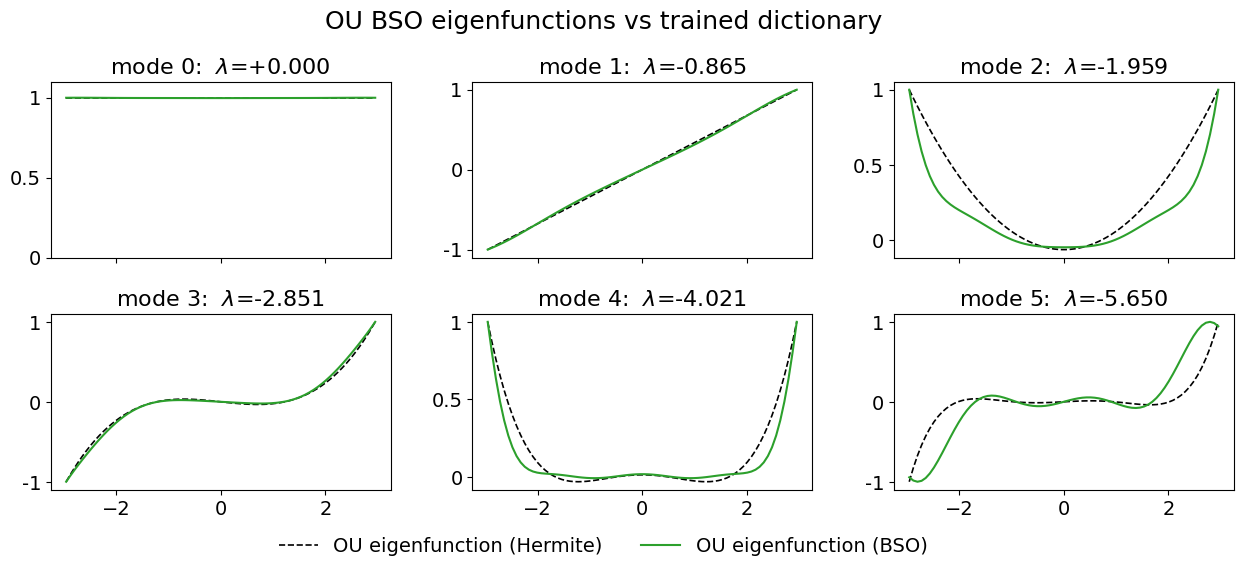


Figure caption:
Postprocessed OU BSO eigenfunctions from the learned dictionary compared with analytic Hermite modes on $|x|\leq 3$. The panels assess parity, nodal structure, and large-scale shape after polynomial projection, parity symmetrization, normalization, and sign alignment.


In [ ]:
import torch
from edmd_bso_method import apply_operator, device

M_STEPS = 4
DEG = 10
grid_d = torch.as_tensor(result_defl.grid, dtype=torch.float32, device=device)
Vp = np.stack([x**k for k in range(DEG + 1)], axis=1)
Qp, _ = np.linalg.qr(Vp * np.sqrt(w)[:, None])
Pp = Qp / np.sqrt(w)[:, None]

fig, axes = plt.subplots(
    2, 3, figsize=OU_GRID_FIGURE["figsize"], dpi=STYLE["dpi"], squeeze=False,
    sharex=True, sharey=False, layout=None, facecolor=STYLE["figure_face_color"],
)
fig.set_layout_engine(None)
for n, ax in enumerate(axes.ravel()):
    j = int(np.argmin(np.abs(lam_d - analytic[n])))
    ef = result_defl.eigenfunctions[j].real
    mu_j = float(np.real(result_defl.mu[j]))
    ef_t = torch.as_tensor(ef.reshape(1, -1), dtype=torch.float32, device=device)
    with torch.no_grad():
        for _ in range(M_STEPS):
            ef_t = apply_operator(result_defl.operator, ef_t, grid_d, result_defl.kind)
    ef = ef_t.squeeze(0).cpu().numpy().astype(np.float64) / (mu_j ** M_STEPS + 1e-300)
    ef = Pp @ ((Pp * w[:, None]).T @ ef)
    ef = 0.5 * (ef + ef[::-1]) if n % 2 == 0 else 0.5 * (ef - ef[::-1])
    coeff = np.zeros(n + 1)
    coeff[-1] = 1.0
    ref = hermeval(x / sigma, coeff)
    efm = ef[mask] / (np.max(np.abs(ef[mask])) + 1e-12)
    refm = ref[mask] / (np.max(np.abs(ref[mask])) + 1e-12)
    if np.linalg.norm(efm - refm) > np.linalg.norm(efm + refm):
        efm = -efm
    ax.plot(xm, refm, color="black", linestyle="--", linewidth=STYLE["line_width"],
            marker=None, label="OU eigenfunction (Hermite)", alpha=1.0, zorder=2)
    ax.plot(xm, efm, color="tab:green", linestyle="-", linewidth=STYLE["line_width"],
            marker=None, label="OU eigenfunction (BSO)", alpha=1.0, zorder=3)
    ax.set_title(rf"mode {n}:  $\lambda$={lam_d[j].real:+.3f}",
                 fontsize=STYLE["panel_title_size"], fontweight=STYLE["title_weight"],
                 pad=STYLE["panel_title_pad"], color=STYLE["text_color"])
    ax.yaxis.set_major_formatter(tick_fmt)
    if n == 0:
        ax.set_ylim(0, 1.1)
    style_axis(ax, grid_axis="both", grid_visible=True, minor_ticks=False)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="lower center", ncol=OU_GRID_FIGURE["legend_ncol"],
    bbox_to_anchor=(0.5, OU_GRID_FIGURE["legend_bottom_in"] / OU_GRID_FIGURE["figsize"][1]),
    frameon=STYLE["legend_frameon"], fancybox=STYLE["legend_fancybox"],
    framealpha=STYLE["legend_framealpha"], borderaxespad=STYLE["legend_borderaxespad"],
    borderpad=STYLE["legend_borderpad"], labelspacing=STYLE["legend_labelspacing"],
    handlelength=STYLE["legend_handlelength"], handleheight=STYLE["legend_handleheight"],
    handletextpad=STYLE["legend_handletextpad"], columnspacing=STYLE["legend_columnspacing"],
    fontsize=STYLE["legend_size"],
)
fig.suptitle(
    "OU BSO eigenfunctions vs trained dictionary",
    fontsize=STYLE["suptitle_size"], fontweight=STYLE["title_weight"],
    color=STYLE["text_color"], x=0.5,
    y=y_from_top(fig, OU_GRID_FIGURE["suptitle_top_in"]),
    horizontalalignment="center", verticalalignment="top",
)
apply_physical_layout(fig, OU_GRID_FIGURE)
save_figure_pair(fig, FIGURES_DIR / 'ou' / 'ou_exp2_eigenfunctions.pdf', dpi=STYLE["dpi"])
plt.show()
print_figure_caption(
    r"Postprocessed OU BSO eigenfunctions from the learned dictionary compared with analytic Hermite modes on $|x|\leq 3$. The panels assess parity, nodal structure, and large-scale shape after polynomial projection, parity symmetrization, normalization, and sign alignment."
)